# The baseline model

RF-DETR Large fine-tuned on the full dataset (`baselines/rf-detr/config.toml`), scored on
the test split: 5,583 pictures from places no training picture shows. Training curves come
from the run's log; every score below from the model's predictions on the test pictures
(`mobdataset evaluate`), scored with the COCO tools.

**Summary**
- Test mAP50-95 0.602 and mAP50 0.741 on 5,583 pictures from places the model never saw.
- At score 0.5 it finds 73 % of the mobs, 5 % of those with the wrong class, with 751
  false alarms over all test pictures.
- Size is what limits it: mobs within 8 blocks score 0.78, past 128 blocks 0.12; boxes
  8 pixels tall or less 0.06, over 128 pixels 0.84.
- Aerial pictures are the hardest (0.33), then under water (0.48); caves score best
  (0.74). Time of day and weather change the score by less than 0.04.
- The weakest classes are small water mobs with few labels (tropical fish, pufferfish,
  tadpole); the most common mix-up is ghast and happy ghast.
- 26 pictures per second on one RTX 4070 (batch 8, resizing included).

In [1]:
import json
import os
import tomllib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as Shown
from IPython.display import display

from mobdataset.analysis import (
    coco_scores,
    draw_predictions,
    grid,
    load_tables,
    match,
    read_pictures,
)
from mobdataset.paths import DATA, ROOT

DATASET = DATA / "datasets" / os.environ.get("NOTEBOOK_DATASET", "full")
RUN = Path(os.environ.get("NOTEBOOK_RUN", DATA / "runs" / "rfdetr-large_full"))
BASELINE = ROOT / "baselines" / "rf-detr"
FIGURES = ROOT / "docs" / "img"
FIGURES.mkdir(parents=True, exist_ok=True)
THRESHOLD = 0.5  # score at which a box counts as a detection in the pictures and mix-ups

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 150,
        "savefig.bbox": "tight",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "font.size": 10,
    }
)


def save(fig: plt.Figure, name: str) -> None:
    """Save a figure for the README (docs/img/<name>.png)."""
    fig.savefig(FIGURES / f"{name}.png")


def show(path: Path) -> None:
    """Show a saved JPEG; displaying the PIL image would also embed a far larger PNG copy."""
    display(Shown(filename=str(path)))


pictures, objects = load_tables(DATASET)
test_pictures = pictures[pictures.split == "test"]
test_labels = objects[(objects.split == "test") & (objects.iscrowd == 0)]
gt = json.loads((DATASET / "annotations" / "test.coco.json").read_text(encoding="utf-8"))
predictions = pd.read_parquet(RUN / "predictions-test.parquet")
speed = json.loads((RUN / "predictions-test.json").read_text(encoding="utf-8"))
print(
    f"{len(test_pictures):,} test pictures, {len(test_labels):,} labels, "
    f"{len(predictions):,} predicted boxes"
)

5,583 test pictures, 19,903 labels, 1,533,863 predicted boxes


## 1. Training

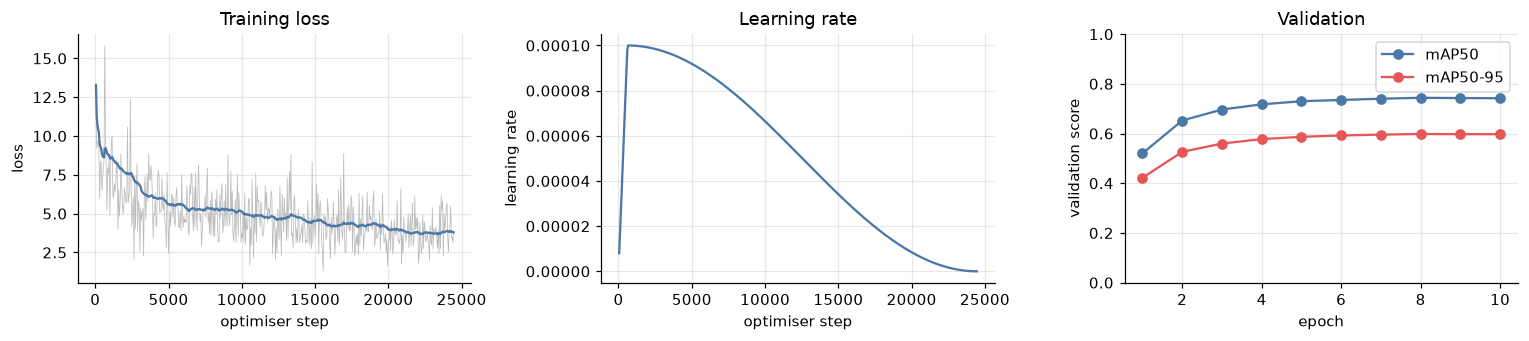

In [2]:
log = pd.read_csv(BASELINE / "metrics.csv")
steps = log.dropna(subset=["train/loss_step"])
val = log.dropna(subset=["val/mAP_50"]).groupby("epoch").last()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
axes[0].plot(steps.step, steps["train/loss_step"], color="#bbbbbb", lw=0.5)
axes[0].plot(
    steps.step, steps["train/loss_step"].rolling(50, min_periods=1).mean(), color="#4c78a8"
)
axes[0].set(xlabel="optimiser step", ylabel="loss", title="Training loss")
axes[1].plot(steps.step, steps["train/lr"], color="#4c78a8")
axes[1].set(xlabel="optimiser step", ylabel="learning rate", title="Learning rate")
epochs = val.index + 1
axes[2].plot(epochs, val["val/mAP_50"], "o-", label="mAP50", color="#4c78a8")
axes[2].plot(epochs, val["val/mAP_50_95"], "o-", label="mAP50-95", color="#e45756")
axes[2].set(xlabel="epoch", ylabel="validation score", title="Validation", ylim=(0, 1))
axes[2].legend()
fig.tight_layout()
save(fig, "training")
plt.show()

**Figure 1. Training.** Loss per step (grey) with its 50-step mean; the learning rate
warms up over a quarter epoch and decays to 0; validation flattens from epoch 7 while the
training loss still falls, so more epochs of the same data would add little.

## 2. Test scores

In [3]:
overall = coco_scores(gt, predictions, per_class=True)
logged = {
    "mAP50-95": log["test/mAP_50_95"].dropna().iloc[-1],
    "mAP50": log["test/mAP_50"].dropna().iloc[-1],
    "mAP75": log["test/mAP_75"].dropna().iloc[-1],
}
table = pd.DataFrame(
    {"these predictions": {k: overall[k] for k in ("mAP50-95", "mAP50", "mAP75", "AR100")},
     "training run's test": logged}
).round(3)  # fmt: skip
display(table)
print(
    f"speed: {speed['pictures_per_second']} pictures per second on {speed['gpu']} "
    f"(batch {speed['batch']})"
)

,these predictions,training run's test
mAP50-95,0.602,0.601
mAP50,0.741,0.740
mAP75,0.644,0.643
AR100,0.715,NaN


speed: 26.08 pictures per second on NVIDIA GeForce RTX 4070 (batch 8)


**Table 1. Test scores**, from the saved predictions and from the training run's own test
at its end; they agree. (That one keeps up to 500 boxes per picture instead of COCO's 100,
which barely matters here.)

## 3. Per class

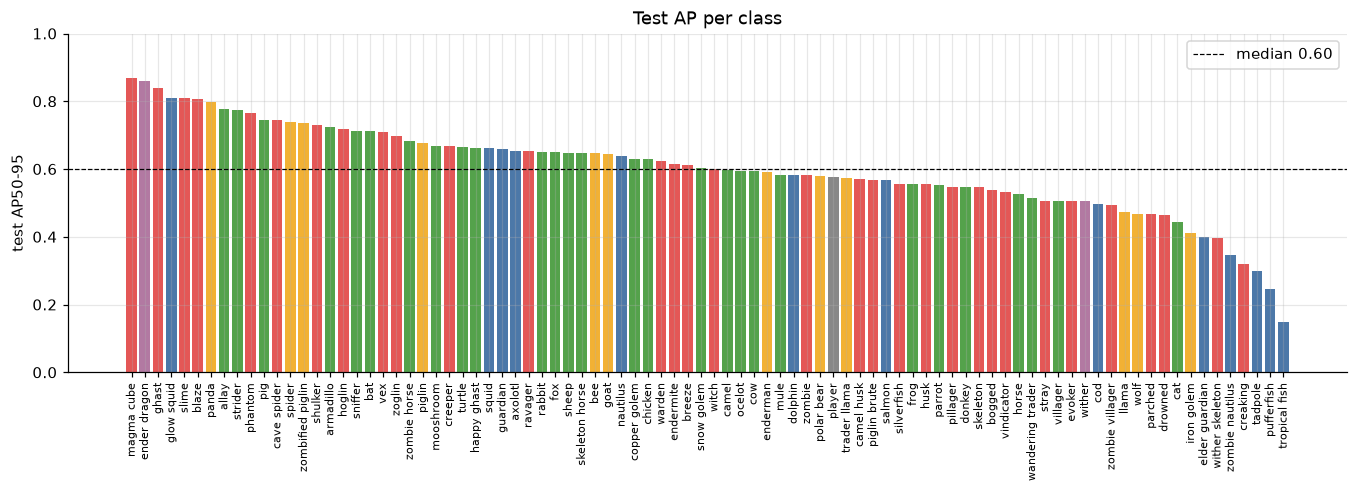

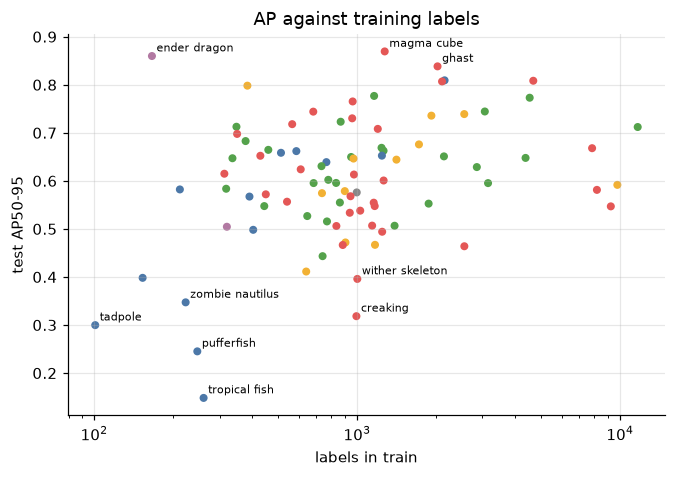

In [4]:
groups = tomllib.loads((ROOT / "config" / "mobs" / "mobs-1.21.11.toml").read_text(encoding="utf-8"))
group_of = {m: g for g in ("hostile", "neutral", "passive", "water", "boss") for m in groups[g]}
GROUP_COLOURS = {"hostile": "#e45756", "neutral": "#f2b134", "passive": "#54a24b",
                 "water": "#4c78a8", "boss": "#b279a2", "player": "#888888"}  # fmt: skip
ap = pd.Series(overall["classes"]).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(15, 4))
ax.bar(ap.index.str.replace("_", " "), ap.to_numpy(),
       color=[GROUP_COLOURS[group_of.get(c, "player")] for c in ap.index])  # fmt: skip
ax.axhline(ap.median(), color="black", lw=0.8, ls="--", label=f"median {ap.median():.2f}")
ax.set(ylabel="test AP50-95", title="Test AP per class", ylim=(0, 1))
ax.tick_params(axis="x", rotation=90, labelsize=7)
ax.legend()
save(fig, "ap_per_class")
plt.show()

train_counts = objects[(objects.split == "train") & (objects.iscrowd == 0)].category.value_counts()
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(train_counts.reindex(ap.index), ap, s=18,
           c=[GROUP_COLOURS[group_of.get(c, "player")] for c in ap.index])  # fmt: skip
for name in list(ap.index[:3]) + list(ap.index[-6:]):
    ax.annotate(name.replace("_", " "), (train_counts[name], ap[name]), fontsize=7,
                xytext=(3, 3), textcoords="offset points")  # fmt: skip
ax.set(
    xscale="log",
    xlabel="labels in train",
    ylabel="test AP50-95",
    title="AP against training labels",
)
save(fig, "ap_vs_labels")
plt.show()

**Figure 2. Test AP per class**, coloured by group. **Figure 3. AP against how many
training labels the class has.** Past about a thousand labels more helps little. The
weakest classes are small water mobs with few labels (tropical fish, pufferfish, tadpole,
zombie nautilus) and look-alikes (creaking, wither skeleton); the ender dragon has the
fewest labels of the land mobs and is among the best, because it is big.

## 4. By kind of picture

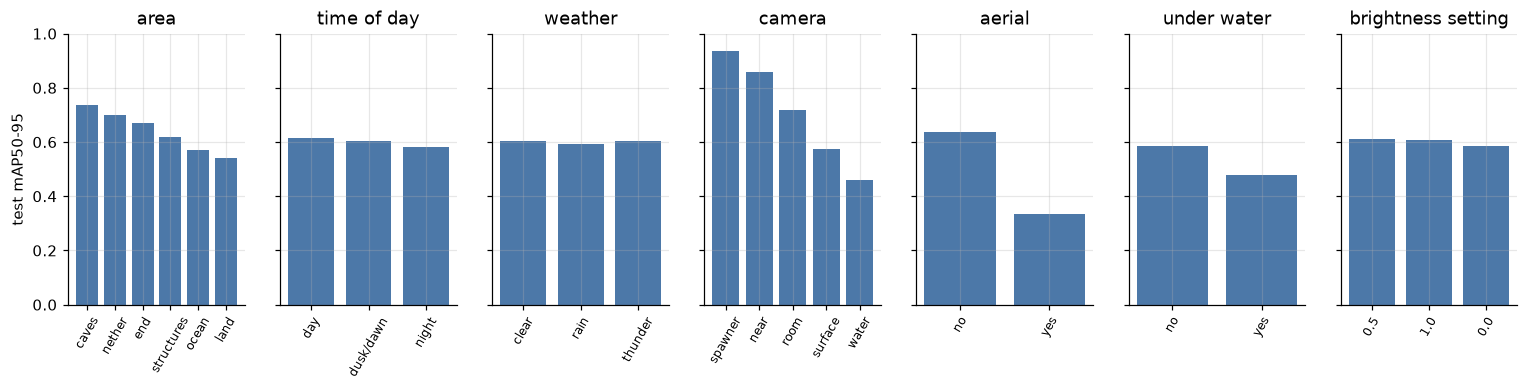

pictures   labels  mAP50  mAP50-95
by                 value                                         
area               caves          707.0   1753.0  0.837     0.738
                   nether         409.0   1371.0  0.787     0.700
                   end            176.0    766.0  0.819     0.672
                   structures     868.0   3201.0  0.743     0.618
                   ocean          528.0   1722.0  0.709     0.569
                   land          2895.0  11090.0  0.687     0.541
time of day        day           2969.0  10764.0  0.756     0.615
                   dusk_dawn      615.0   2161.0  0.740     0.605
                   night         1999.0   6978.0  0.710     0.581
weather            clear         4190.0  14811.0  0.745     0.605
                   rain           975.0   3535.0  0.724     0.591
                   thunder        418.0   1557.0  0.721     0.605
camera             spawner         40.0     79.0  0.986     0.936
                   near            20.0    100.0  0.955     0.858
                   room          1336.0   3803.0  0.815     0.719
                   surface       4079.0  15593.0  0.721     0.575
                   water          108.0    328.0  0.606     0.461
aerial             no            4870.0  17335.0  0.772     0.638
                   yes            713.0   2568.0  0.503     0.333
under water        no            5352.0  19135.0  0.727     0.585
                   yes            231.0    768.0  0.580     0.479
brightness setting 0.5           2626.0   9508.0  0.753     0.613
                   1.0           1703.0   6379.0  0.748     0.606
                   0.0           1254.0   4016.0  0.713     0.587

In [5]:
def by_picture(column: str, order: list[str] | None = None) -> pd.DataFrame:
    rows = {}
    for value, frame in test_pictures.groupby(column):
        s = coco_scores(gt, predictions, image_ids=frame.image_id)
        # As text: in one table True and 1.0 would be the same row label.
        if isinstance(value, (bool, np.bool_)):
            value = "yes" if value else "no"
        rows[str(value)] = {
            "pictures": len(frame),
            "labels": s["labels"],
            "mAP50": s["mAP50"],
            "mAP50-95": s["mAP50-95"],
        }
    out = pd.DataFrame(rows).T
    return out.reindex(order) if order else out.sort_values("mAP50-95", ascending=False)


breakdowns = {
    "area": by_picture("area"),
    "time of day": by_picture("time", ["day", "dusk_dawn", "night"]),
    "weather": by_picture("weather", ["clear", "rain", "thunder"]),
    "camera": by_picture("camera_kind"),
    "aerial": by_picture("aerial"),
    "under water": by_picture("underwater"),
    "brightness setting": by_picture("brightness"),
}
fig, axes = plt.subplots(1, len(breakdowns), figsize=(17, 3.2), sharey=True)
for ax, (name, frame) in zip(axes, breakdowns.items(), strict=True):
    frame = frame.dropna(subset=["mAP50-95"])
    ax.bar([str(i).replace("_", "/") for i in frame.index], frame["mAP50-95"], color="#4c78a8")
    ax.set(title=name, ylim=(0, 1))
    ax.tick_params(axis="x", rotation=60, labelsize=8)
axes[0].set_ylabel("test mAP50-95")
save(fig, "ap_by_picture")
plt.show()
display(pd.concat(breakdowns, names=["by", "value"]).round(3))

**Figure 4 and Table 2. Test mAP50-95 by kind of picture.** *Brightness setting*: the
game's Brightness slider of the window that took the picture (0 Moody, 0.5 default,
1 Bright).

## 5. By mob: distance, size, how much is seen

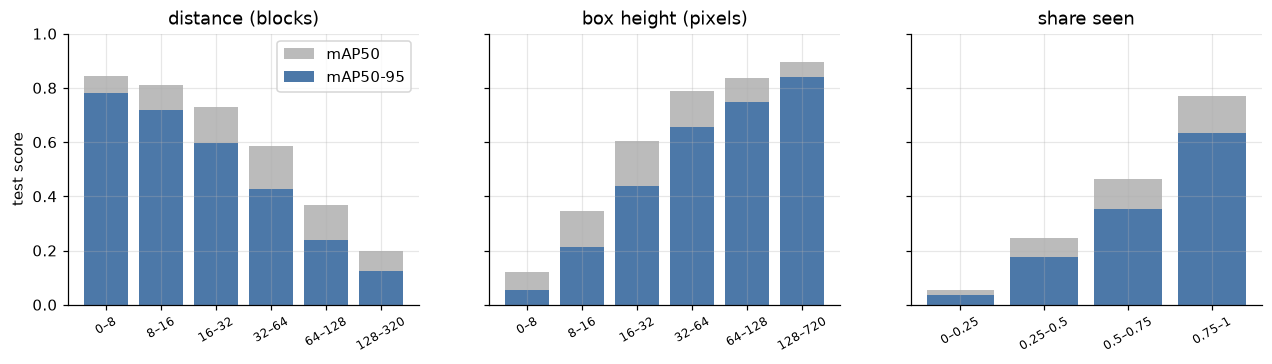

labels  mAP50  mAP50-95
by                  bucket                            
distance (blocks)   0–8        3168.0  0.845     0.782
                    8–16       3952.0  0.811     0.717
                    16–32      4276.0  0.729     0.597
                    32–64      4027.0  0.586     0.426
                    64–128     2875.0  0.369     0.237
                    128–320    1605.0  0.198     0.123
box height (pixels) 0–8        2220.0  0.119     0.055
                    8–16       3478.0  0.345     0.213
                    16–32      4096.0  0.605     0.438
                    32–64      3908.0  0.790     0.654
                    64–128     3349.0  0.836     0.748
                    128–720    2852.0  0.895     0.841
share seen          0–0.25      541.0  0.055     0.038
                    0.25–0.5   1170.0  0.245     0.174
                    0.5–0.75   2784.0  0.465     0.352
                    0.75–1    15408.0  0.770     0.635

In [6]:
def by_label(name: str, values: pd.Series, bins: list[float]) -> pd.DataFrame:
    names = [f"{lo:g}–{hi:g}" for lo, hi in zip(bins, bins[1:], strict=False)]
    buckets = pd.cut(values, bins, labels=names, include_lowest=True)
    rows = {}
    for bucket, ids in test_labels.id.groupby(buckets, observed=True):
        s = coco_scores(gt, predictions, keep=ids)
        rows[str(bucket)] = {"labels": s["labels"], "mAP50": s["mAP50"], "mAP50-95": s["mAP50-95"]}
    return pd.DataFrame(rows).T.rename_axis(name)


by_mob = {
    "distance (blocks)": by_label("distance", test_labels.distance, [0, 8, 16, 32, 64, 128, 320]),
    "box height (pixels)": by_label("height", test_labels.h, [0, 8, 16, 32, 64, 128, 720]),
    "share seen": by_label("seen", test_labels.visible_share.fillna(1), [0, 0.25, 0.5, 0.75, 1]),
}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), sharey=True)
for ax, (name, frame) in zip(axes, by_mob.items(), strict=True):
    ax.bar(frame.index, frame["mAP50"], color="#bbbbbb", label="mAP50")
    ax.bar(frame.index, frame["mAP50-95"], color="#4c78a8", label="mAP50-95")
    ax.set(title=name, ylim=(0, 1))
    ax.tick_params(axis="x", rotation=30, labelsize=8)
axes[0].set_ylabel("test score")
axes[0].legend()
save(fig, "ap_by_mob")
plt.show()
display(pd.concat(by_mob, names=["by", "bucket"]).round(3))

**Figure 5 and Table 3. Test scores by the mob's distance, size in the picture and how
much of it is seen.** Other labels are ignore regions in each bucket, so a bucket is scored
on its own mobs only.

## 6. Mix-ups

In [7]:
sure = predictions[predictions.score >= THRESHOLD]
pairs = match(test_labels, sure)
found = pairs.dropna(subset=["label", "predicted"])
wrong = found[found.label != found.predicted]
print(f"at score {THRESHOLD}: {pairs.label.notna().sum():,} labels, "
      f"{len(found):,} found ({len(found) / pairs.label.notna().sum():.1%}), "
      f"{len(wrong):,} of those with a wrong class, "
      f"{pairs.label.isna().sum():,} false alarms")  # fmt: skip
top = wrong.groupby(["label", "predicted"]).size().sort_values(ascending=False).head(15)
display(top.rename("times").to_frame())

at score 0.5: 19,903 labels, 14,613 found (73.4%), 737 of those with a wrong class, 751 false alarms


,,times
label,predicted,
happy_ghast,ghast,26
ghast,happy_ghast,23
goat,sheep,13
sheep,pig,11
wither_skeleton,enderman,10
stray,skeleton,8
pig,armadillo,7
cat,wolf,6
cow,pig,6


**Table 4. The most common mix-ups** at score 0.5: a label found in the right place but
given another class.

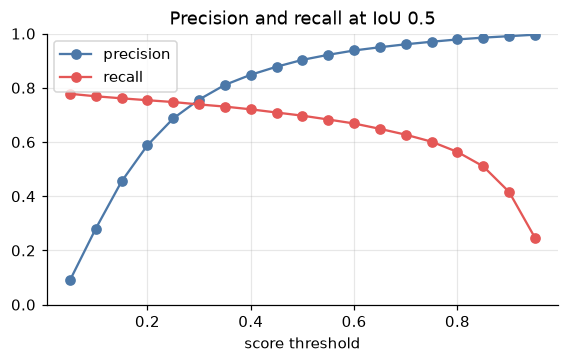

In [8]:
thresholds = np.linspace(0.05, 0.95, 19)
curve = []
for t in thresholds:
    p = match(test_labels, predictions[predictions.score >= t])
    hits = ((p.label == p.predicted) & p.label.notna()).sum()
    curve.append({"threshold": t, "precision": hits / max(p.predicted.notna().sum(), 1),
                  "recall": hits / p.label.notna().sum()})  # fmt: skip
curve = pd.DataFrame(curve)
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(curve.threshold, curve.precision, "o-", label="precision", color="#4c78a8")
ax.plot(curve.threshold, curve.recall, "o-", label="recall", color="#e45756")
ax.set(xlabel="score threshold", ylim=(0, 1), title="Precision and recall at IoU 0.5")
ax.legend()
save(fig, "threshold")
plt.show()

**Figure 6. Precision and recall by score threshold** (a hit: right class, IoU at least
0.5).

## 7. Pictures

Green: right; red: wrong class or nothing there; yellow: a mob the model missed.

best


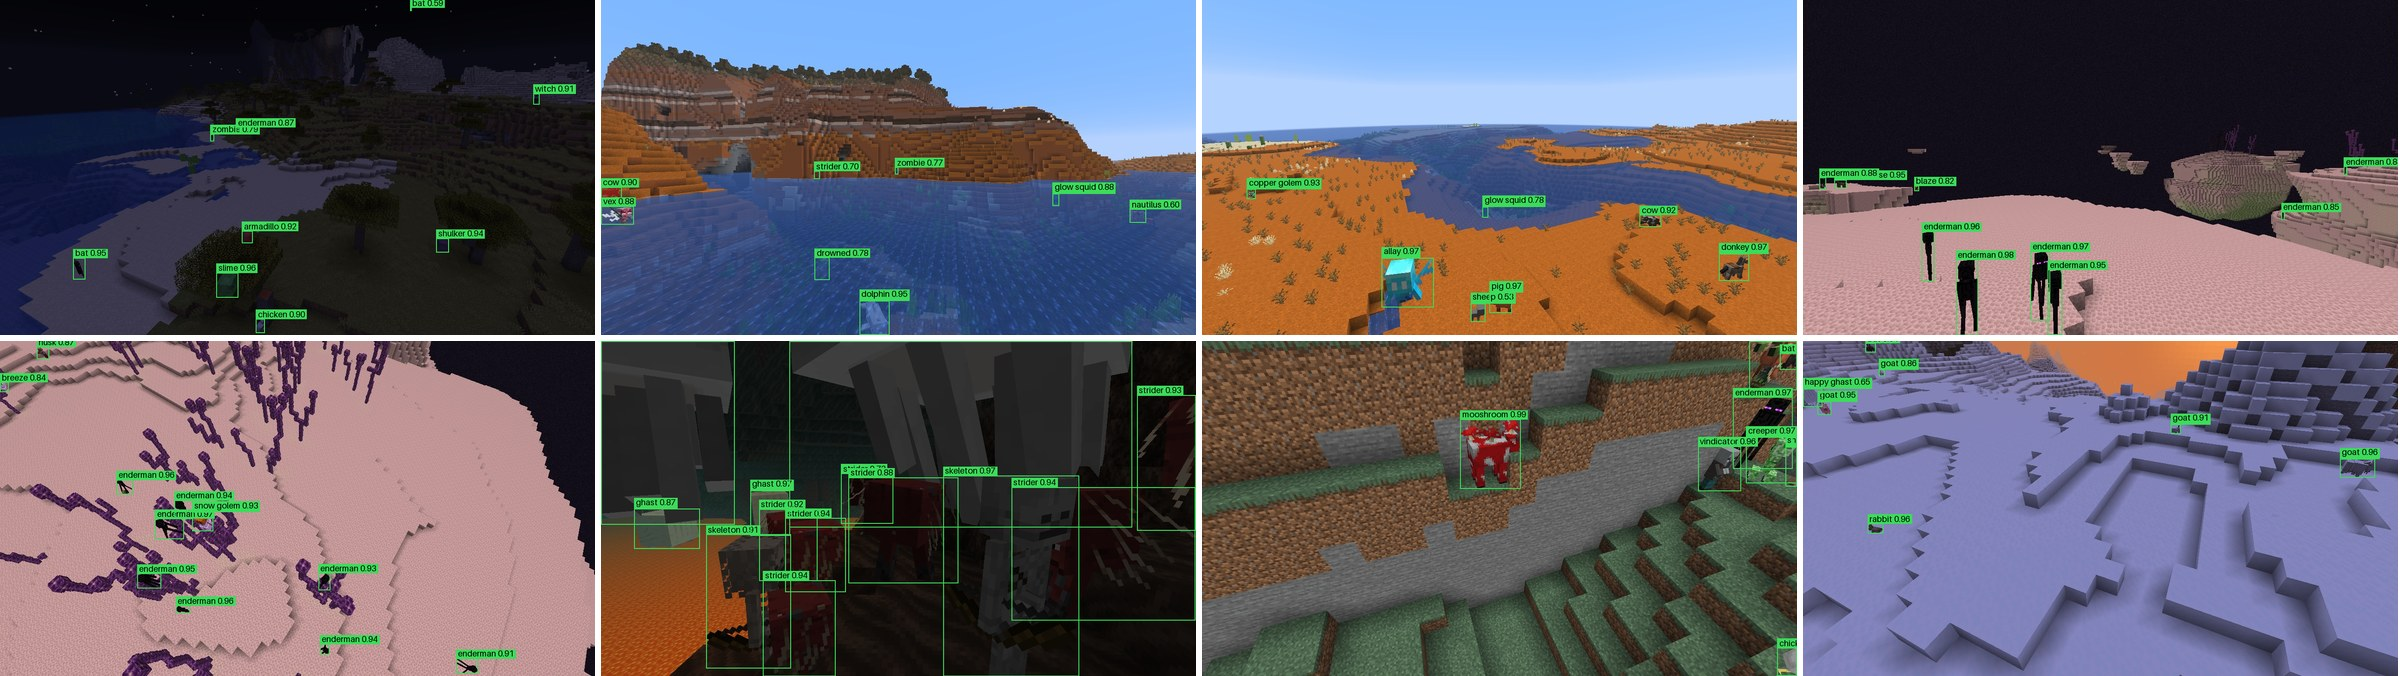

worst


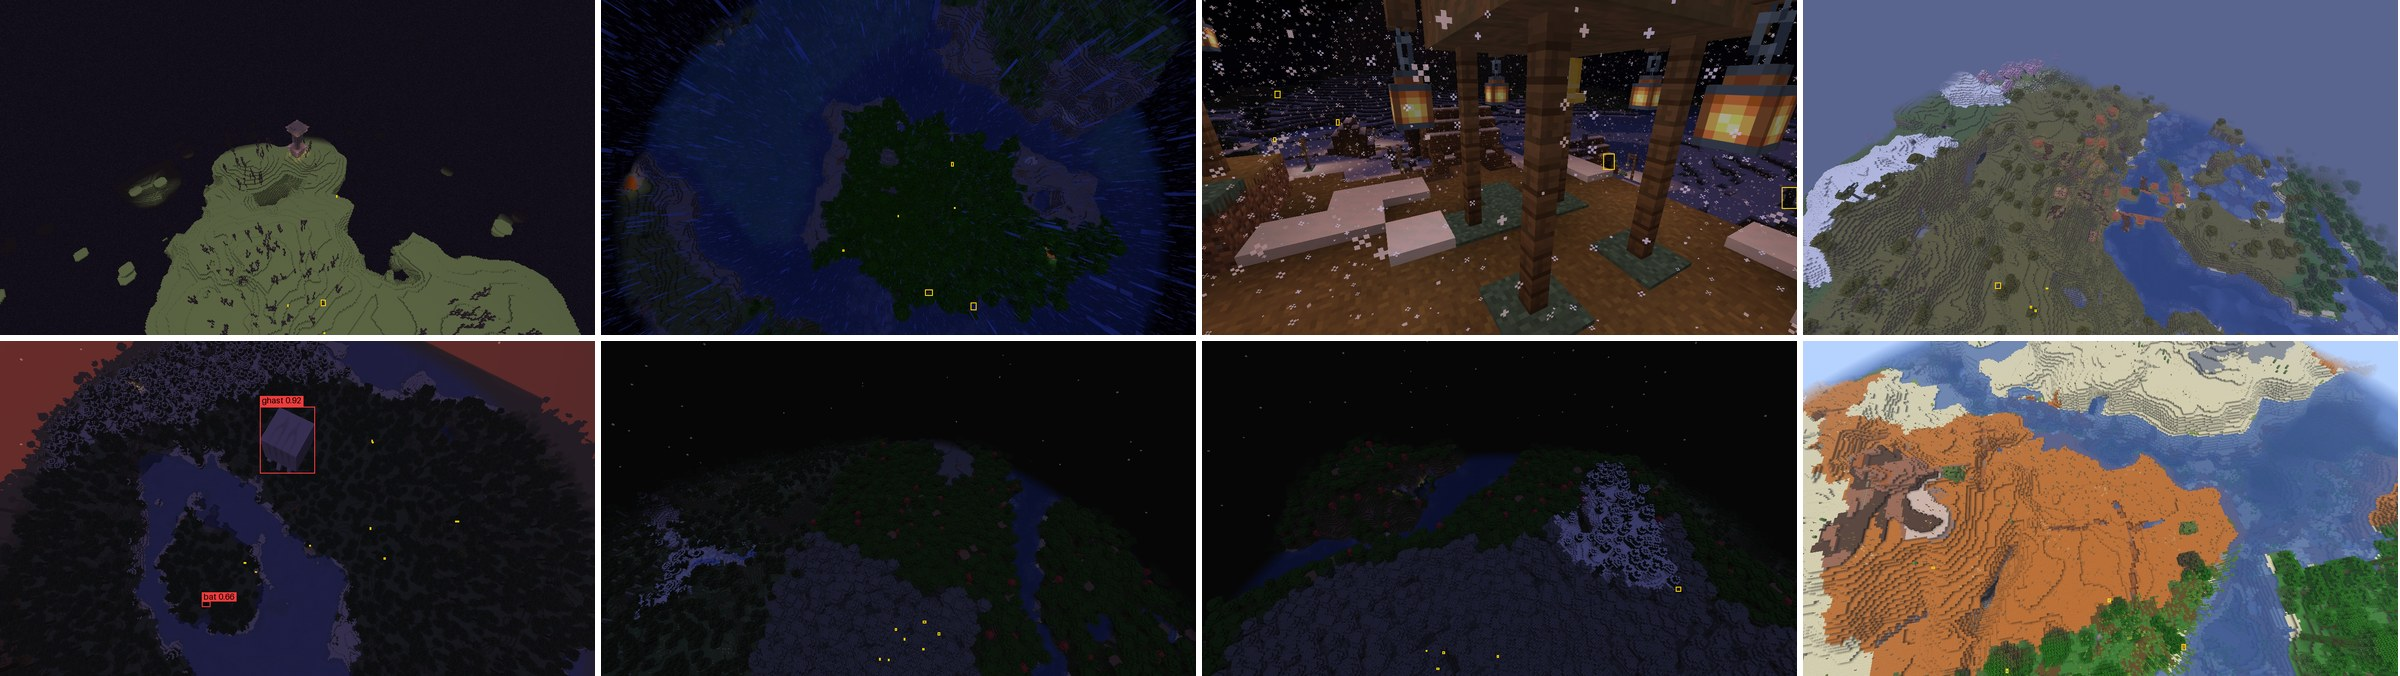

In [9]:
per_picture = (
    pairs.assign(
        hit=(pairs.label == pairs.predicted) & pairs.label.notna(),
        label_n=pairs.label.notna(),
        pred_n=pairs.predicted.notna(),
    )
    .groupby("image_id")[["hit", "label_n", "pred_n"]]
    .sum()
)
per_picture["f1"] = 2 * per_picture.hit / (per_picture.label_n + per_picture.pred_n).clip(lower=1)
busy = per_picture[per_picture.label_n >= 4]
best = busy.sort_values(["f1", "label_n"], ascending=False).head(60).sample(8, random_state=0).index
worst = busy.sort_values("f1").head(8).index
rows = read_pictures(DATASET, [*best, *worst])
by_image = dict(tuple(predictions.groupby("image_id")))
for name, ids in (("best", best), ("worst", worst)):
    image = grid([draw_predictions(rows[i], by_image.get(i, predictions.iloc[0:0]), THRESHOLD)
                  for i in ids if i in rows], columns=4, width=2400)  # fmt: skip
    image.save(FIGURES / f"predictions_{name}.jpg", quality=88)
    print(name)
    show(FIGURES / f"predictions_{name}.jpg")

**Figure 7. Test pictures the model gets right** (first: busy pictures with every mob
found) **and wrong** (second: the lowest share found), at score 0.5. The worst are aerial
pictures whose mobs are a few pixels across.